**Business Problem**

Imagine you are working as a Data Scientist for a telecom company.

The company is losing customers every month.

**Management wants to answer:**

**"Which customers are likely to leave the company, and what factors are causing customers to leave?"**

Your job is to build an ML model that predicts whether a customer will Churn = Yes/No.

**Business objective**
*  Identify customers who are likely to leave.
* Understand the reasons behind churn.
* Target high-risk customers with retention offers.
* Reduce customer loss.
* Increase customer lifetime value.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             roc_auc_score,
                             confusion_matrix,
                             classification_report,
                             roc_curve)
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df=pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**EDA**

In [ ]:
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [ ]:
# TotalCharges contains some blank values.
# Convert it to numeric
# coerce : If Python cannot convert a value into a number, replace it with NaN instead of giving an error.

df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [ ]:
# Fill missing TotalCharges using median

df["TotalCharges"]=df["TotalCharges"].fillna(df["TotalCharges"].median())
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
print("================ TARGET DISTRIBUTION ================\n")
print(df["Churn"].value_counts())
print("Churn percentage : ",df["Churn"].value_counts(normalize=True)*100)

================ TARGET DISTRIBUTION ================

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn percentage :  Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


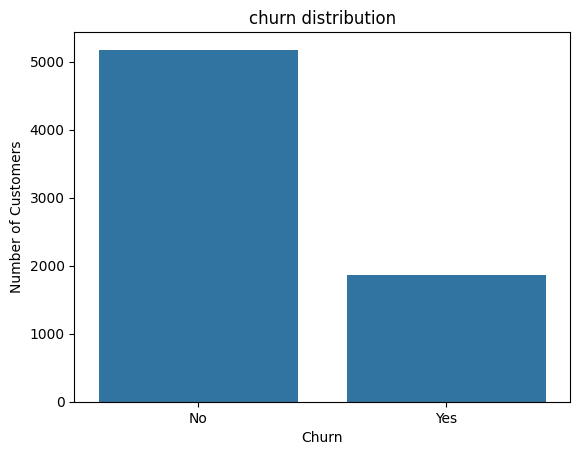

In [ ]:
# EDA - CHURN COUNT

sns.countplot(x=df["Churn"])
plt.title("churn distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

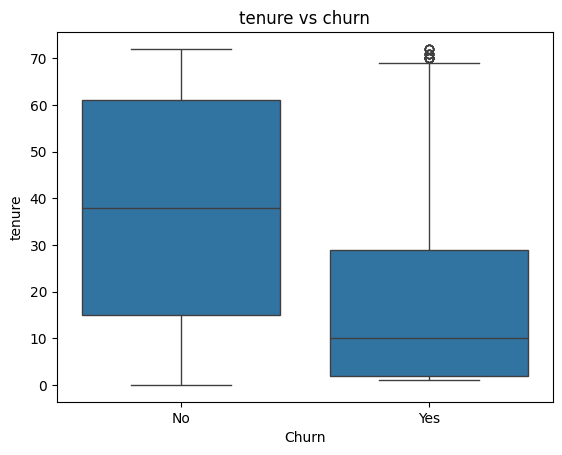

In [ ]:
# EDA - TENURE (no of month that costomer has)VS CHURN

sns.boxplot(x=df["Churn"],y=df["tenure"])
plt.title("tenure vs churn")
plt.xlabel("Churn")
plt.ylabel("tenure")
plt.show()

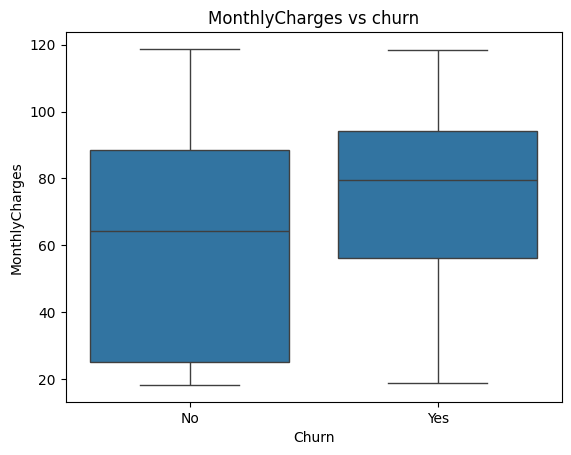

In [ ]:
# MONTHLY CHARGES VS CHURN

sns.boxplot(x=df["Churn"],y=df["MonthlyCharges"])
plt.title("MonthlyCharges vs churn")
plt.xlabel("Churn")
plt.ylabel("MonthlyCharges")
plt.show()

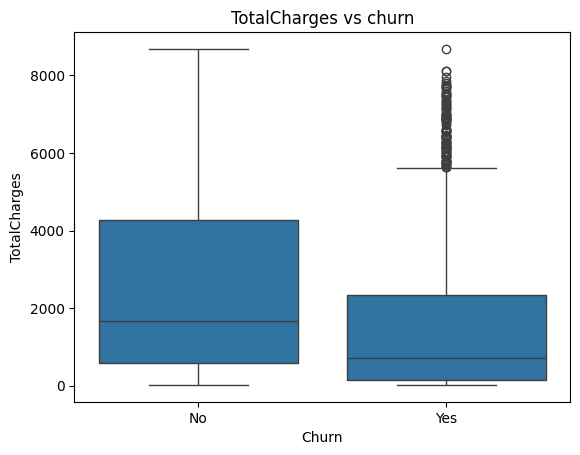

In [ ]:
# TOTAL CHARGES VS CHURN

sns.boxplot(x=df["Churn"],y=df["TotalCharges"])
plt.title("TotalCharges vs churn")
plt.xlabel("Churn")
plt.ylabel("TotalCharges")
plt.show()

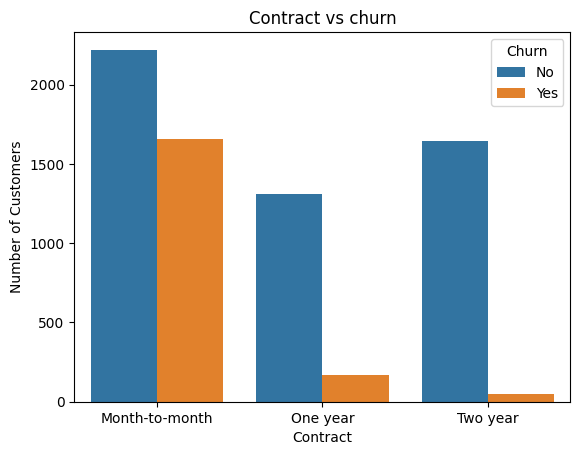

In [ ]:
# CONTRACT VS CHURN

sns.countplot(x=df["Contract"],hue=df["Churn"])
plt.title("Contract vs churn")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")
plt.show()

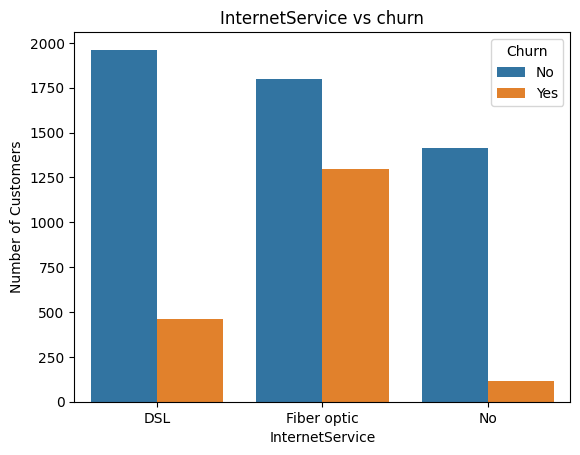

In [ ]:
# INTERNET SERVICE VS CHURN

sns.countplot(x=df['InternetService'],hue=df['Churn'])
plt.title("InternetService vs churn")
plt.xlabel("InternetService")
plt.ylabel("Number of Customers")
plt.show()

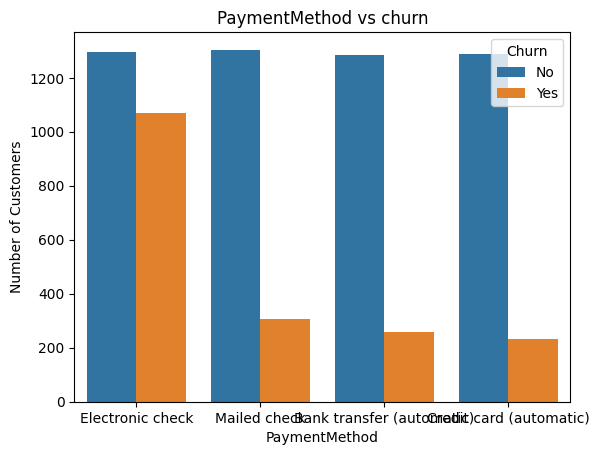

In [ ]:
#  PAYMENT METHOD VS CHURN

sns.countplot(x=df['PaymentMethod'],hue=df['Churn'])
plt.title("PaymentMethod vs churn")
plt.xlabel("PaymentMethod")
plt.ylabel("Number of Customers")
plt.show()

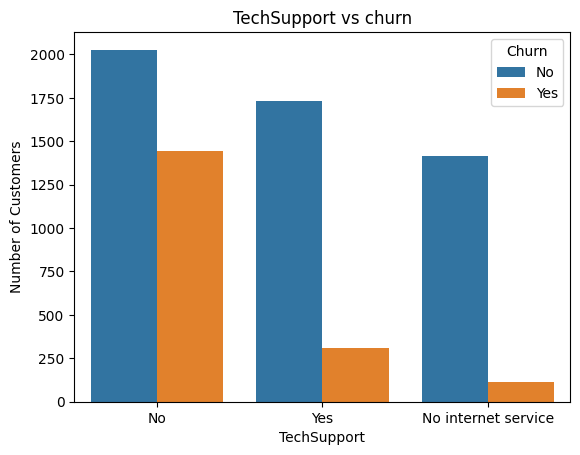

In [ ]:
# TECH SUPPORT VS CHURN

sns.countplot(x=df['TechSupport'],hue=df['Churn'])
plt.title("TechSupport vs churn")
plt.xlabel("TechSupport")
plt.ylabel("Number of Customers")
plt.show()

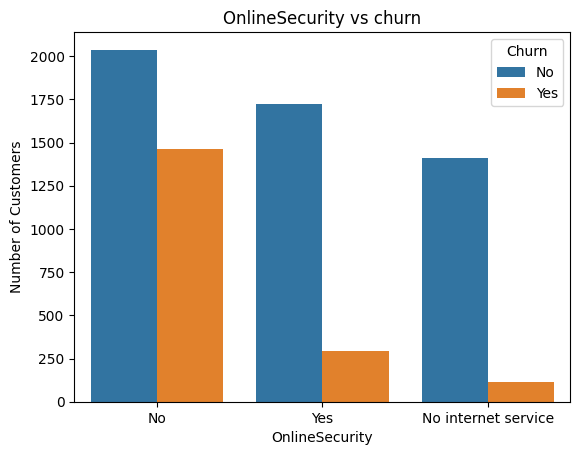

In [ ]:
#  ONLINE SECURITY VS CHURN

sns.countplot(x=df['OnlineSecurity'],hue=df['Churn'])
plt.title("OnlineSecurity vs churn")
plt.xlabel("OnlineSecurity")
plt.ylabel("Number of Customers")
plt.show()

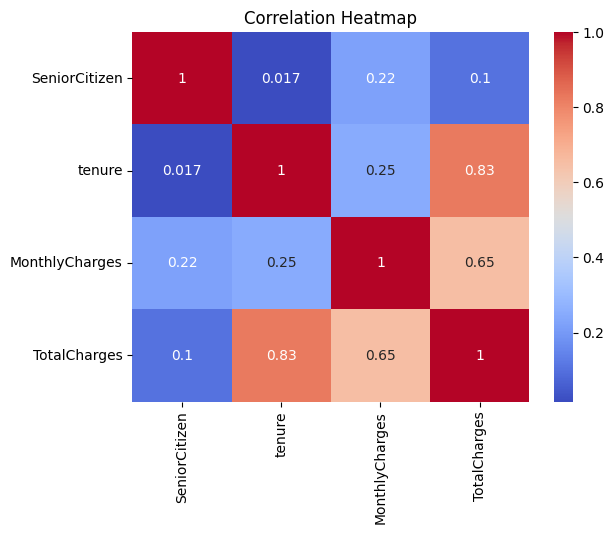

In [ ]:
# CORRELATION HEATMAP

numeric_columns=df.select_dtypes(include=np.number)

sns.heatmap(numeric_columns.corr(),annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# CONVERT TARGET VARIABLE

df["Churn"]=df["Churn"].map({"Yes":1,"No":0})
print("target after encoding:")
print(df["Churn"].value_counts())

target after encoding:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
# REMOVE CUSTOMER ID
# customerID does not provide useful predictive information

df=df.drop("customerID",axis=1)

In [ ]:
df.shape

(7043, 20)

In [ ]:
# SEPARATE X AND y

X=df.drop("Churn",axis=1)
y=df["Churn"]

print(X.shape)
print(y.shape)

(7043, 19)
(7043,)


In [ ]:
# ENCODE CATEGORICAL VARIABLES

X=pd.get_dummies(X,drop_first=True)
print("after encoding:")
print(X.head())
print("number of features after encoding:")
print(X.shape[1])

after encoding:
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
0              0       1           29.85         29.85        False   
1              0      34           56.95       1889.50         True   
2              0       2           53.85        108.15         True   
3              0      45           42.30       1840.75         True   
4              0       2           70.70        151.65        False   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0         True           False             False   
1        False           False              True   
2        False           False              True   
3        False           False             False   
4        False           False              True   

   MultipleLines_No phone service  MultipleLines_Yes  ...  \
0                            True              False  ...   
1                           False              False  ...   
2                           False              False  ...   


In [ ]:
# TRAIN TEST SPLIT
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print(X_train.shape)
print(X_test.shape)

(5634, 30)
(1409, 30)


In [ ]:
# FEATURE SCALING

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [ ]:
# create models

logistic_model=LogisticRegression(
    max_iter=1000,
    random_state=42
)

knn_model=KNeighborsClassifier(
    n_neighbors=5
)

decision_tree_model=DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

random_forest_model=RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

xgb_model=XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)

In [ ]:
# model train

logistic_model.fit(X_train_scaled,y_train)
print("logistic regrassion trained")

knn_model.fit(X_train_scaled,y_train)
print("KNN trained")

decision_tree_model.fit(X_train_scaled,y_train)
print("decision tree trained")

random_forest_model.fit(X_train_scaled,y_train)
print("rondom forest trained")

xgb_model.fit(X_train_scaled,y_train)
print("xgboost trained")

logistic regrassion trained
KNN trained
decision tree trained
rondom forest trained
xgboost trained


In [ ]:
# Logistic Regression Prediction

y_pred_lr=logistic_model.predict(X_test_scaled)
y_prob_lr=logistic_model.predict_proba(X_test_scaled)[:,1]

print("logistic regrassion")

print("Accuracy:",accuracy_score(y_test,y_pred_lr))
print("Precision:",precision_score(y_test,y_pred_lr))
print("Recall:",recall_score(y_test,y_pred_lr))
print("F1 Score:",f1_score(y_test,y_pred_lr))
print("ROC AUC Score:",roc_auc_score(y_test,y_prob_lr))

logistic regrassion
Accuracy: 0.8069552874378992
Precision: 0.6583850931677019
Recall: 0.5668449197860963
F1 Score: 0.6091954022988506
ROC AUC Score: 0.8415846443979436


In [ ]:
# KNN prediction

y_pred_knn = knn_model.predict(X_test_scaled)

y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

print("KNN")

print("Accuracy:",
      accuracy_score(y_test, y_pred_knn))

print("Precision:",
      precision_score(y_test, y_pred_knn))

print("Recall:",
      recall_score(y_test, y_pred_knn))

print("F1 Score:",
      f1_score(y_test, y_pred_knn))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_knn))

KNN
Accuracy: 0.7473385379701917
Precision: 0.5252808988764045
Recall: 0.5
F1 Score: 0.5123287671232877
ROC-AUC: 0.7716035030613035


In [ ]:
# Decision Tree prediction

y_pred_dt = decision_tree_model.predict(X_test)

y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree")

print("Accuracy:",
      accuracy_score(y_test, y_pred_dt))

print("Precision:",
      precision_score(y_test, y_pred_dt))

print("Recall:",
      recall_score(y_test, y_pred_dt))

print("F1 Score:",
      f1_score(y_test, y_pred_dt))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_dt))

Decision Tree
Accuracy: 0.7345635202271115
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.7367253093595805


In [ ]:
# Random Forest prediction

y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest")

print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Precision:",
      precision_score(y_test, y_pred_rf))

print("Recall:",
      recall_score(y_test, y_pred_rf))

print("F1 Score:",
      f1_score(y_test, y_pred_rf))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf))

Random Forest
Accuracy: 0.7331440738112136
Precision: 0.25
Recall: 0.00267379679144385
F1 Score: 0.005291005291005291
ROC-AUC: 0.7376837427988324


In [ ]:
# XGBoost prediction

y_pred_xgb = xgb_model.predict(X_test)

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost")

print("Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

print("Precision:",
      precision_score(y_test, y_pred_xgb))

print("Recall:",
      recall_score(y_test, y_pred_xgb))

print("F1 Score:",
      f1_score(y_test, y_pred_xgb))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_xgb))

XGBoost
Accuracy: 0.7345635202271115
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.5546423312407968


In [ ]:
# confusion matrix

import seaborn as sns
import matplotlib.pyplot as plt
cm=confusion_matrix(y_test,y_pred_rf)
print(cm)

[[1032    3]
 [ 373    1]]


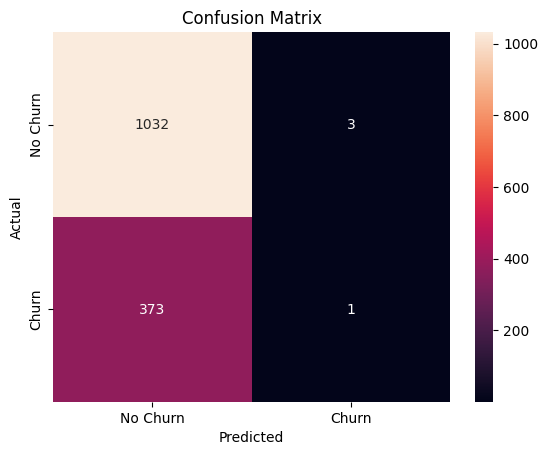

In [ ]:
# Visualize it:

sns.heatmap(cm,annot=True,fmt="d",xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_knn),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

print(comparison)

                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.806955   0.658385  0.566845  0.609195  0.841585
1                  KNN  0.747339   0.525281  0.500000  0.512329  0.771604
2        Decision Tree  0.734564   0.000000  0.000000  0.000000  0.736725
3        Random Forest  0.733144   0.250000  0.002674  0.005291  0.737684
4              XGBoost  0.734564   0.000000  0.000000  0.000000  0.554642


In [ ]:
# find best model

best_model=comparison.loc[comparison["ROC-AUC"].idxmax()]
print("Best model:",best_model)

Best model: Model        Logistic Regression
Accuracy                0.806955
Precision               0.658385
Recall                  0.566845
F1 Score                0.609195
ROC-AUC                 0.841585
Name: 0, dtype: object


In [ ]:
from sklearn.metrics import roc_curve

# Logistic Regression
fpr_lr, tpr_lr, threshold_lr = roc_curve(
    y_test,
    y_prob_lr
)

# KNN
fpr_knn, tpr_knn, threshold_knn = roc_curve(
    y_test,
    y_prob_knn
)

# Decision Tree
fpr_dt, tpr_dt, threshold_dt = roc_curve(
    y_test,
    y_prob_dt
)

# Random Forest
fpr_rf, tpr_rf, threshold_rf = roc_curve(
    y_test,
    y_prob_rf
)

# XGBoost
fpr_xgb, tpr_xgb, threshold_xgb = roc_curve(
    y_test,
    y_prob_xgb
)

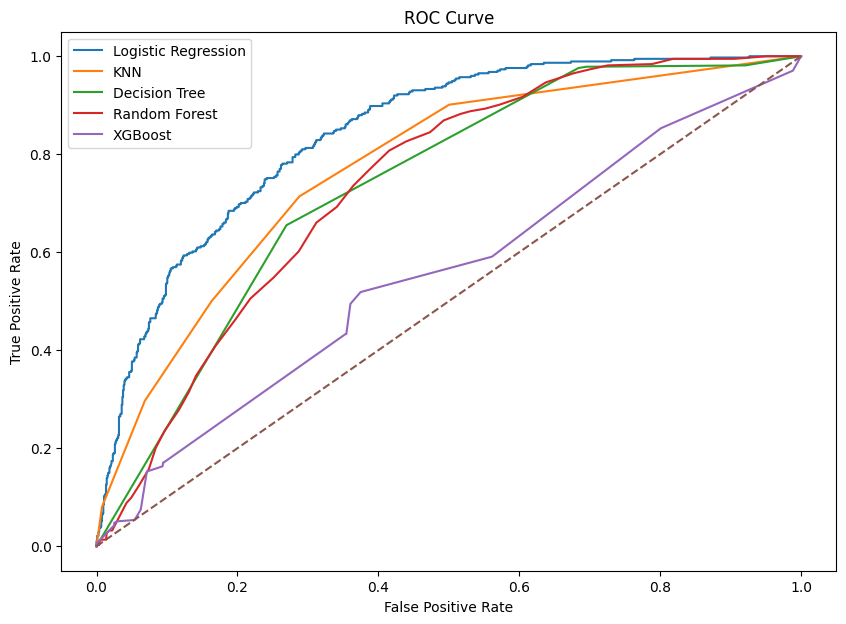

In [ ]:
plt.figure(figsize=(10, 7))

plt.plot(
    fpr_lr,
    tpr_lr,
    label="Logistic Regression"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label="KNN"
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label="Decision Tree"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label="Random Forest"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

**Feature Importance**

In [ ]:
importance=random_forest_model.feature_importances_
feature_names=X.columns
feature_importance=pd.DataFrame({
    "Feature":feature_names,
    "Importance":importance
})
feature_importance=feature_importance.sort_values(by="Importance",ascending=False)
print(feature_importance)

                                  Feature  Importance
3                            TotalCharges    0.192096
1                                  tenure    0.174733
2                          MonthlyCharges    0.168413
28         PaymentMethod_Electronic check    0.038771
10            InternetService_Fiber optic    0.038641
25                      Contract_Two year    0.030176
4                             gender_Male    0.028321
13                     OnlineSecurity_Yes    0.028191
26                   PaperlessBilling_Yes    0.025617
5                             Partner_Yes    0.023326
19                        TechSupport_Yes    0.022209
24                      Contract_One year    0.021710
15                       OnlineBackup_Yes    0.021431
0                           SeniorCitizen    0.020484
9                       MultipleLines_Yes    0.019969
6                          Dependents_Yes    0.019751
17                   DeviceProtection_Yes    0.018984
21                        St

**Hyperparameter Tuning**

In [ ]:
from sklearn.model_selection import GridSearchCV
# create parameter
param_grid={
    "n_estimators":[100,200],
    "max_depth":[3,5,7],
    "min_samples_split":[2,5]
}
# create gridsearch
grid_search=GridSearchCV(
    RandomForestClassifier(
        random_state=42
    ),
    param_grid,
    cv=5,
    scoring="roc_auc"
)
# train
grid_search.fit(
    X_train,
    y_train
)
# find best parameters
print("best parameter:")
print(grid_search.best_params_)
#best score
print("best score:")
print(grid_search.best_score_)

best parameter:
{'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 200}
best score:
0.8449939632330719


**Test the Tuned Model**

In [ ]:
best_rf=grid_search.best_estimator_
y_pred_best_rf=best_rf.predict(X_test)
y_prob_best_rf=best_rf.predict_proba(X_test)[:,1]

print("Tuned Random Forest")

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_best_rf)
)

print(
    "Precision:",
    precision_score(y_test, y_pred_best_rf)
)

print(
    "Recall:",
    recall_score(y_test, y_pred_best_rf)
)

print(
    "F1 Score:",
    f1_score(y_test, y_pred_best_rf)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_best_rf)
)

Tuned Random Forest
Accuracy: 0.7977288857345636
Precision: 0.6745098039215687
Recall: 0.45989304812834225
F1 Score: 0.5468998410174881
ROC-AUC: 0.8439691027926322


**Final Confusion Matrix**

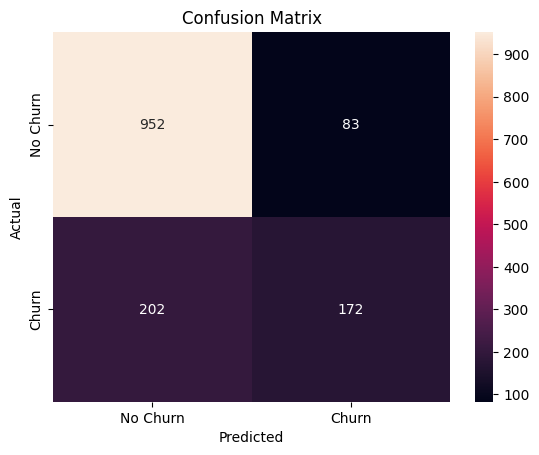

In [ ]:
cm=confusion_matrix(y_test,y_pred_best_rf)

sns.heatmap(cm,
            annot=True,
            fmt="d",
            xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**Predict a New Customer**

In [ ]:
new_customer = pd.DataFrame({
    "gender": ["Female"],
    "SeniorCitizen": [0],
    "Partner": ["No"],
    "Dependents": ["No"],
    "tenure": [2],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["No"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["Yes"],
    "StreamingMovies": ["Yes"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [80],
    "TotalCharges": [160]
})
new_customers=pd.get_dummies(new_customer)
new_customer=new_customer.reindex(
    columns=X.columns,
    fill_value=0
)
prediction=best_rf.predict(new_customer)
probability = best_rf.predict_proba(
    new_customer
)[0][1]

print("Churn Probability:")

print(
    probability * 100,
    "%"
)
if prediction[0] == 1:
    print("Customer is likely to CHURN")
else:
    print("Customer is likely to STAY")

Churn Probability:
45.465303392793395 %
Customer is likely to STAY


In [ ]:
test_data = X_test.copy()

test_data["Actual_Churn"] = y_test.values

test_data["Predicted_Churn"] = y_pred_best_rf

test_data["Churn_Probability"] = y_prob_best_rf

print(test_data.head())

      SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
437               0      72          114.05       8468.20         True   
2280              1       8          100.15        908.55        False   
2235              0      41           78.35       3211.20        False   
4460              0      18           78.20       1468.75         True   
3761              0      72           82.65       5919.35        False   

      Partner_Yes  Dependents_Yes  PhoneService_Yes  \
437          True            True              True   
2280        False           False              True   
2235         True            True              True   
4460         True           False              True   
3761         True           False              True   

      MultipleLines_No phone service  MultipleLines_Yes  ...  \
437                            False               True  ...   
2280                           False               True  ...   
2235                           F